In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('data/car_details.csv')
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
data = pd.DataFrame()

data['y'] = df['selling_price']

data['x1'] = df['year']
data['x2'] = df['km_driven']
data['x3'] = (df['transmission'] == 'Manual').astype(int)

high_price = data['y'].quantile(0.95)
data = data[data['y'].between(0, high_price)]
print(len(data))

4136


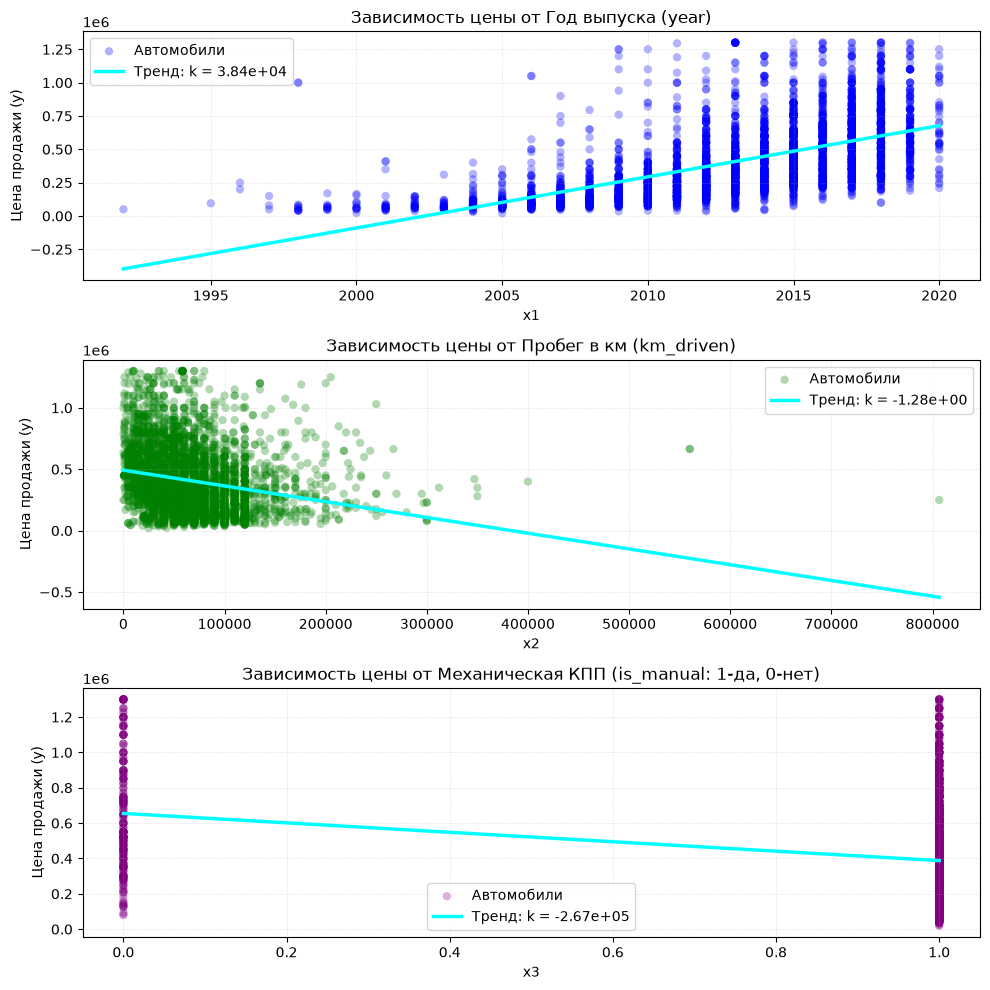

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

features = [
    ('x1', 'Год выпуска (year)', 'blue'),
    ('x2', 'Пробег в км (km_driven)', 'green'),
    ('x3', 'Механическая КПП (is_manual: 1-да, 0-нет)', 'purple')
]

for ax, (col, title, color) in zip(axes, features):
    x = data[col]
    y = data['y']

    k, b = np.polyfit(x, y, deg=1)

    ax.scatter(x, y, color=color, alpha=0.3, edgecolors='none', label='Автомобили')

    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, k * x_line + b, color= 'cyan', linewidth=2.5,
            label=f'Тренд: k = {k:.2e}')

    ax.set_title(f'Зависимость цены от {title}')
    ax.set_xlabel(col)
    ax.set_ylabel('Цена продажи (y)')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.show()

In [5]:
import statsmodels.api as sm

X = data[['x1', 'x2', 'x3']]
Y = data['y']


X_with_const = sm.add_constant(X)

model = sm.OLS(Y, X_with_const).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.405
Model:                            OLS   Adj. R-squared:                  0.404
Method:                 Least Squares   F-statistic:                     936.7
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:08:16   Log-Likelihood:                -56503.
No. Observations:                4136   AIC:                         1.130e+05
Df Residuals:                    4132   BIC:                         1.130e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7.653e+07   1.69e+06    -45.295      0.0

In [6]:
from scipy import stats

df_resid = int(model.df_resid)

gamma_levels = [0.90, 0.95, 0.99]

ci_results = []

for gamma in gamma_levels:
    alpha = 1 - gamma
    t_crit = stats.t.ppf(1 - alpha / 2, df_resid)

    for var in model.params.index:
        coef = model.params[var]
        se = model.bse[var]

        ci_lower = coef - t_crit * se
        ci_upper = coef + t_crit * se

        ci_results.append({
            'Уровень доверия (gamma)': f"{gamma * 100:.0f}%",
            't_крит': round(t_crit, 3),
            'Переменная': var,
            'Оценка (coef)': f"{coef:,.2f}",
            'Станд. ошибка (se)': f"{se:,.3f}",
            'Нижняя граница': f"{ci_lower:,.2f}",
            'Верхняя граница': f"{ci_upper:,.2f}"
        })

ci_df = pd.DataFrame(ci_results)
display(ci_df)

,Уровень доверия (gamma),t_крит,Переменная,Оценка (coef),Станд. ошибка (se),Нижняя граница,Верхняя граница
0,90%,1.645,const,"-76,530,094.62","1,689,594.693","-79,309,853.79","-73,750,335.44"
1,90%,1.645,x1,"38,314.57",838.052,"36,935.79","39,693.35"
2,90%,1.645,x2,0.23,0.075,0.11,0.35
3,90%,1.645,x3,"-218,593.10","12,811.005","-239,670.06","-197,516.15"
4,95%,1.961,const,"-76,530,094.62","1,689,594.693","-79,842,609.68","-73,217,579.56"
5,95%,1.961,x1,"38,314.57",838.052,"36,671.54","39,957.61"
6,95%,1.961,x2,0.23,0.075,0.08,0.38
7,95%,1.961,x3,"-218,593.10","12,811.005","-243,709.57","-193,476.64"
8,99%,2.577,const,"-76,530,094.62","1,689,594.693","-80,884,213.41","-72,175,975.82"
9,99%,2.577,x1,"38,314.57",838.052,"36,154.90","40,474.25"


In [8]:
from scipy import stats
f_obs = model.fvalue
df_num = int(model.df_model)
df_denom = int(model.df_resid)
gamma_list = [0.90, 0.95, 0.99]
f_test_results = []
for gamma in gamma_list:
    alpha = 1 - gamma
    f_crit = stats.f.ppf(1 - alpha, df_num, df_denom)

    is_significant = f_obs > f_crit

    f_test_results.append({
        'Уровень надежности (gamma)': f"{gamma * 100:.0f}%",
        'Уровень значимости (alpha)': f"{alpha:.2f}",
        'F_расч': f"{f_obs:.2f}",
        'F_крит': f"{f_crit:.3f}",
        'F_расч > F_крит?': "Да" if is_significant else "Нет",
        'Вывод о значимости R^2': "R^2 значим (модель адекватна)" if is_significant else "Не значим"
    })
f_table = pd.DataFrame(f_test_results)
display(f_table)

,Уровень надежности (gamma),Уровень значимости (alpha),F_расч,F_крит,F_расч > F_крит?,Вывод о значимости R^2
0,90%,0.10,936.72,2.085,Да,R^2 значим (модель адекватна)
1,95%,0.05,936.72,2.607,Да,R^2 значим (модель адекватна)
2,99%,0.01,936.72,3.786,Да,R^2 значим (модель адекватна)


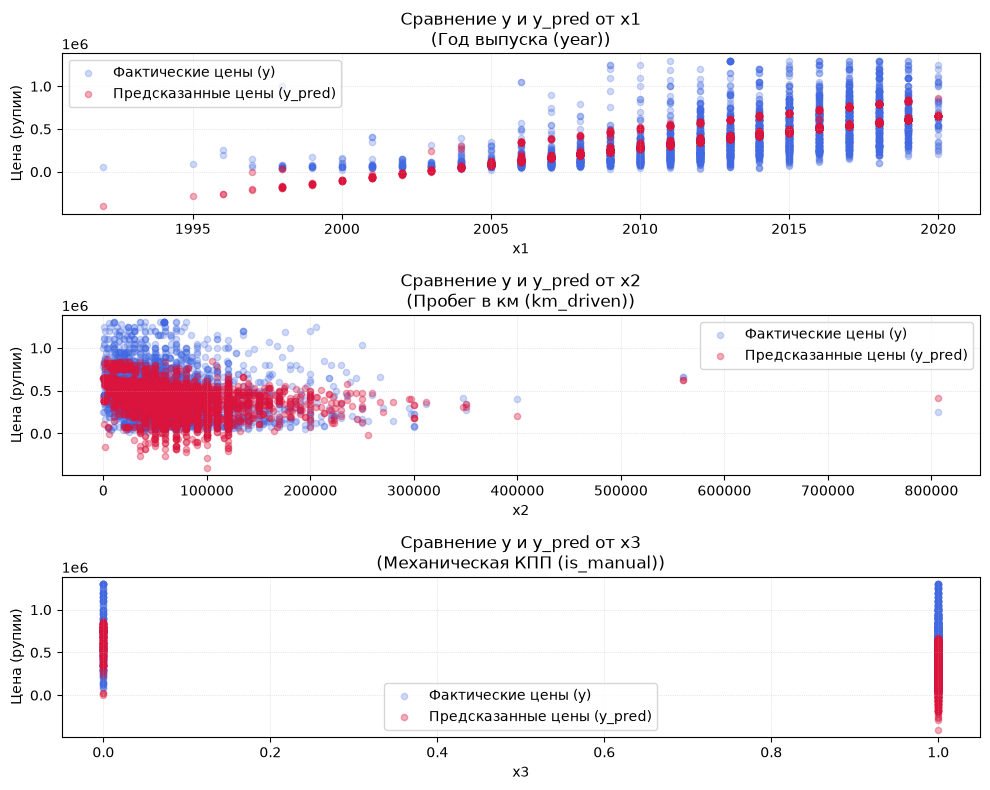

In [11]:
data['y_pred'] = model.fittedvalues
data['residuals'] = model.resid

fig, axes = plt.subplots(3, 1, figsize=(11, 11))

features = [
    ('x1', 'Год выпуска (year)'),
    ('x2', 'Пробег в км (km_driven)'),
    ('x3', 'Механическая КПП (is_manual)')
]

for ax, (col, title) in zip(axes, features):
    ax.scatter(data[col], data['y'], color='royalblue', alpha=0.25, s=20, label='Фактические цены (y)')

    ax.scatter(data[col], data['y_pred'], color='crimson', alpha=0.35, s=20, label='Предсказанные цены (y_pred)')

    ax.set_title(f'Сравнение y и y_pred от {col}\n({title})')
    ax.set_xlabel(col)
    ax.set_ylabel('Цена (рупии)')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.show()

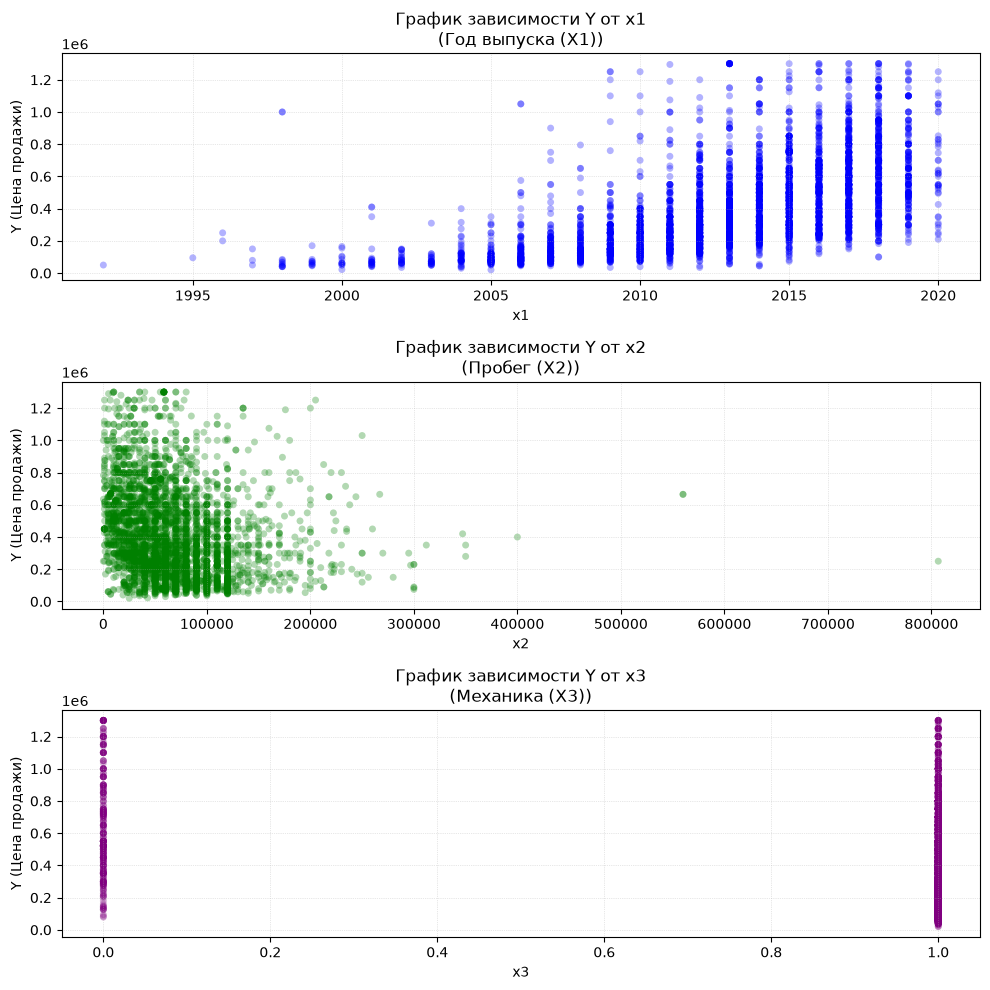

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(10, 10))

pairs = [
    ('x1', 'Год выпуска (X1)', 'blue'),
    ('x2', 'Пробег (X2)', 'green'),
    ('x3', 'Механика (X3)', 'purple')
]

for ax, (var, label, color) in zip(axes, pairs):
    ax.scatter(data[var], data['y'], color=color, alpha=0.3, edgecolors='none', s=25)
    ax.set_title(f'График зависимости Y от {var}\n({label})', fontsize=12)
    ax.set_xlabel(var)
    ax.set_ylabel('Y (Цена продажи)')
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [17]:
import statsmodels.api as sm
import pandas as pd

X_unrestricted = sm.add_constant(data[['x1', 'x2', 'x3']])
Y = data['y']

model_unrestricted = sm.OLS(Y, X_unrestricted).fit()

print(model_unrestricted.summary())

summary_table_p5 = pd.DataFrame({
    'Параметр': ['C (a0)', 'X1 (a1)', 'X2 (a2)', 'X3 (a3)'],
    'Коэффициент': model_unrestricted.params.values,
    'Станд. ошибка': model_unrestricted.bse.values,
    't-статистика': model_unrestricted.tvalues.values,
    'p-value (Prob)': model_unrestricted.pvalues.values
})

print("\n--- Пункт 5.1: Параметры и t-статистики ---")
display(summary_table_p5)

print("\n--- Пункты 5.2 и 5.3: Коэффициенты детерминации и F-статистика ---")
print(f"Обычный R-квадрат (R-squared):             {model_unrestricted.rsquared:.4f}")
print(f"Исправленный R-квадрат (Adjusted R-squared): {model_unrestricted.rsquared_adj:.4f}")
print(f"F-статистика (F-statistic):                 {model_unrestricted.fvalue:.2f}")
print(f"Prob(F-statistic):                          {model_unrestricted.f_pvalue:.4e}")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.405
Model:                            OLS   Adj. R-squared:                  0.404
Method:                 Least Squares   F-statistic:                     936.7
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        03:52:10   Log-Likelihood:                -56503.
No. Observations:                4136   AIC:                         1.130e+05
Df Residuals:                    4132   BIC:                         1.130e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7.653e+07   1.69e+06    -45.295      0.0

,Параметр,Коэффициент,Станд. ошибка,t-статистика,p-value (Prob)
0,C (a0),-7.653009e+07,1.689595e+06,-45.294943,0.000000e+00
1,X1 (a1),3.831457e+04,8.380518e+02,45.718624,0.000000e+00
2,X2 (a2),2.293166e-01,7.542630e-02,3.040274,2.378446e-03
3,X3 (a3),-2.185931e+05,1.281100e+04,-17.062916,3.891761e-63



--- Пункты 5.2 и 5.3: Коэффициенты детерминации и F-статистика ---
Обычный R-квадрат (R-squared):             0.4048
Исправленный R-квадрат (Adjusted R-squared): 0.4044
F-статистика (F-statistic):                 936.72
Prob(F-statistic):                          0.0000e+00


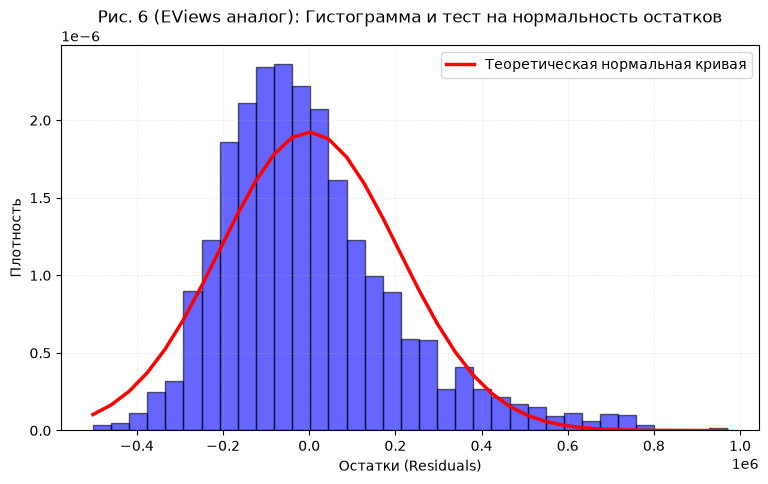

Mean (Среднее):             8.7716e-07
Median (Медиана):           -33710.33
Std. Dev. (СКО):            207416.78
Skewness (Асимметрия):      1.0512
Kurtosis (Эксцесс):         4.6192
Jarque-Bera:                1211.0788
Probability (p-value):      1.0413e-263

Вывод: гипотеза о нормальности остатков ОТВЕРГАЕТСЯ на уровне 0.05 (Prob < 0.05), так как Prob = 1.04e-263. Однако визуально распределение близко к симметричному колоколу.


In [18]:
from scipy import stats
import numpy as np

residuals = model_unrestricted.resid

mean_r = residuals.mean()
median_r = residuals.median()
std_r = residuals.std()
skew_r = residuals.skew()
kurt_r = residuals.kurtosis() + 3
jb_stat, jb_prob = stats.jarque_bera(residuals)

plt.figure(figsize=(9, 5))
n_bins, bins, _ = plt.hist(residuals, bins=35, density=True, color='blue', alpha=0.6, edgecolor='black')

pdf_line = stats.norm.pdf(bins, loc=mean_r, scale=std_r)
plt.plot(bins, pdf_line, color='red', linewidth=2.5, label='Теоретическая нормальная кривая')

plt.title('Рис. 6 (EViews аналог): Гистограмма и тест на нормальность остатков', fontsize=12)
plt.xlabel('Остатки (Residuals)')
plt.ylabel('Плотность')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.show()

print(f"Mean (Среднее):             {mean_r:.4e}")
print(f"Median (Медиана):           {median_r:.2f}")
print(f"Std. Dev. (СКО):            {std_r:.2f}")
print(f"Skewness (Асимметрия):      {skew_r:.4f}")
print(f"Kurtosis (Эксцесс):         {kurt_r:.4f}")
print(f"Jarque-Bera:                {jb_stat:.4f}")
print(f"Probability (p-value):      {jb_prob:.4e}")

alpha = 0.05
if jb_prob >= alpha:
    print(f"\nВывод: гипотеза о нормальности остатков ПРИНИМАЕТСЯ на уровне {alpha} (Prob >= {alpha}).")
else:
    print(f"\nВывод: гипотеза о нормальности остатков ОТВЕРГАЕТСЯ на уровне {alpha} (Prob < {alpha}), "
          f"так как Prob = {jb_prob:.2e}. Однако визуально распределение близко к симметричному колоколу.")

In [19]:
data['x1_plus_x2'] = data['x1'] + data['x2']

X_restr1 = sm.add_constant(data[['x1_plus_x2', 'x3']])
model_restr1 = sm.OLS(Y, X_restr1).fit()

print(model_restr1.summary())

print("\n--- Результаты для модели с ограничением a1 = a2 ---")
print(f"C(1) [Константа]:      {model_restr1.params['const']:,.2f} (t = {model_restr1.tvalues['const']:.2f}, p = {model_restr1.pvalues['const']:.4f})")
print(f"C(2) [при X1 + X2]:    {model_restr1.params['x1_plus_x2']:.4f} (t = {model_restr1.tvalues['x1_plus_x2']:.2f}, p = {model_restr1.pvalues['x1_plus_x2']:.4f})")
print(f"C(4) [при X3]:         {model_restr1.params['x3']:,.2f} (t = {model_restr1.tvalues['x3']:.2f}, p = {model_restr1.pvalues['x3']:.4f})")
print(f"R-squared:             {model_restr1.rsquared:.4f}")
print(f"Adjusted R-squared:    {model_restr1.rsquared_adj:.4f}")
print(f"F-statistic:           {model_restr1.fvalue:.2f} (Prob = {model_restr1.f_pvalue:.4e})")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.104
Model:                            OLS   Adj. R-squared:                  0.103
Method:                 Least Squares   F-statistic:                     239.1
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           5.66e-99
Time:                        03:53:56   Log-Likelihood:                -57350.
No. Observations:                4136   AIC:                         1.147e+05
Df Residuals:                    4133   BIC:                         1.147e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        7.16e+05   1.57e+04     45.518      0.0

In [20]:
data['y_trans'] = data['y'] - 14 * data['x2'] + 2 * data['x3']
data['x1_minus_x2'] = data['x1'] - data['x2']

X_restr2 = sm.add_constant(data[['x1_minus_x2']])
Y_trans = data['y_trans']

model_restr2 = sm.OLS(Y_trans, X_restr2).fit()

print(model_restr2.summary())

c1_hat = model_restr2.params['const']
c2_hat = model_restr2.params['x1_minus_x2']
a1_final = c2_hat
a2_final = 14 - c2_hat
a3_final = -2.0

print("\n--- Пункт 13: Восстановленные параметры модели с ограничениями ---")
print(f"a0 = {c1_hat:,.2f}")
print(f"a1 = {a1_final:.4f}")
print(f"a2 = 14 - a1 = {a2_final:.4f}")
print(f"a3 = {a3_final:.2f}")
print(f"R-squared:          {model_restr2.rsquared:.4f}")
print(f"Adjusted R-squared: {model_restr2.rsquared_adj:.4f}")
print(f"F-statistic:        {model_restr2.fvalue:.2f}")

                            OLS Regression Results                            
Dep. Variable:                y_trans   R-squared:                       0.882
Model:                            OLS   Adj. R-squared:                  0.882
Method:                 Least Squares   F-statistic:                 3.099e+04
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        03:54:17   Log-Likelihood:                -57469.
No. Observations:                4136   AIC:                         1.149e+05
Df Residuals:                    4134   BIC:                         1.150e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        4.618e+05   6976.271     66.190      

In [21]:
comparison_df = pd.DataFrame({
    'Модель': [
        '1. Без ограничений (Y C X1 X2 X3)',
        '2. Ограничение a1 = a2',
        '3. Ограничения a1 + a2 = 14, a3 = -2'
    ],
    'R-squared': [
        f"{model_unrestricted.rsquared:.4f}",
        f"{model_restr1.rsquared:.4f}",
        f"{model_restr2.rsquared:.4f}"
    ],
    'Adj. R-squared': [
        f"{model_unrestricted.rsquared_adj:.4f}",
        f"{model_restr1.rsquared_adj:.4f}",
        f"{model_restr2.rsquared_adj:.4f}"
    ],
    'F-statistic': [
        f"{model_unrestricted.fvalue:.2f}",
        f"{model_restr1.fvalue:.2f}",
        f"{model_restr2.fvalue:.2f}"
    ],
    'RSS (Сумма квадр. остатков)': [
        f"{model_unrestricted.ssr:,.2e}",
        f"{model_restr1.ssr:,.2e}",
        f"{model_restr2.ssr:,.2e}"
    ]
})

print("\nСводное сравнение качества всех трех моделей:")
display(comparison_df)


Сводное сравнение качества всех трех моделей:


,Модель,R-squared,Adj. R-squared,F-statistic,RSS (Сумма квадр. остатков)
0,1. Без ограничений (Y C X1 X2 X3),0.4048,0.4044,936.72,1.78e+14
1,2. Ограничение a1 = a2,0.1037,0.1033,239.07,2.68e+14
2,"3. Ограничения a1 + a2 = 14, a3 = -2",0.8823,0.8823,30986.36,2.84e+14
